# Import Libraries

In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

df = pd.read_csv('/home/raven/Downloads/IST-Assignment/ML_Project_Submission/Data_file - 3.csv')

# EDA
# Disease Distribution

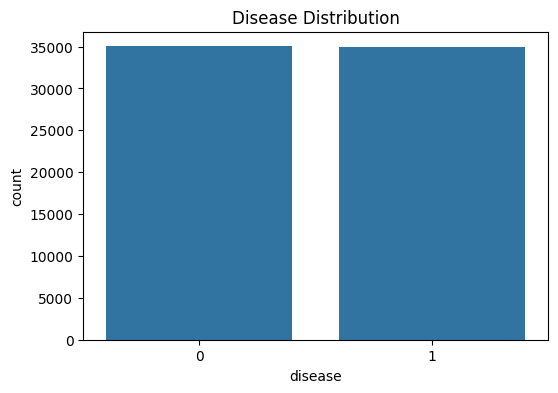

In [7]:
plt.figure(figsize=(6,4))
sns.countplot(x='disease', data=df)
plt.title("Disease Distribution")
plt.show()

# Cholesterol vs Disease

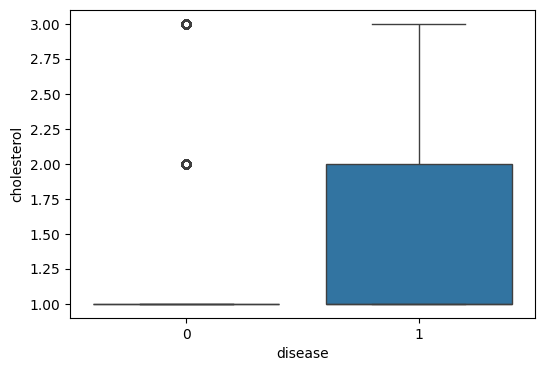

In [8]:
plt.figure(figsize=(6,4))
sns.boxplot(x='disease', y='cholesterol', data=df)
plt.show()

# Correlation Heatmap

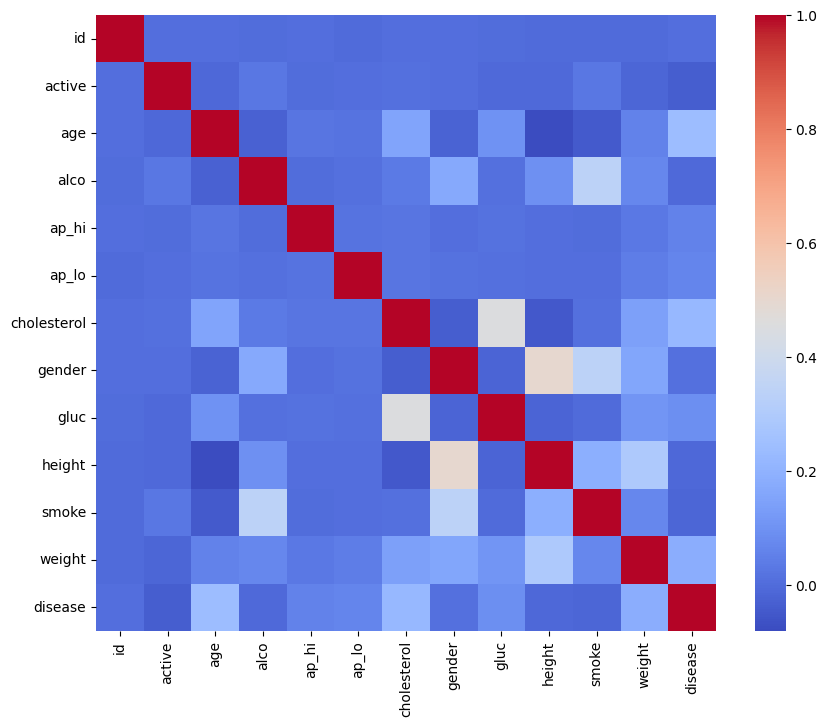

In [9]:
plt.figure(figsize=(10,8))

sns.heatmap(
    df.select_dtypes(include=np.number).corr(),
    cmap='coolwarm'
)

plt.show()

# Preprocessing

# Drop unnecessary columns:

In [10]:
df.drop(
    ['date', 'id'],
    axis=1,
    inplace=True
)

# Encode categorical columns:

In [11]:
le = LabelEncoder()

for col in df.columns:
    if df[col].dtype == 'object':
        df[col] = le.fit_transform(df[col])

# Split Features and Target

In [12]:
X = df.drop('disease', axis=1)

y = df['disease']

In [13]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

# Scale features:

In [14]:
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)

X_test = scaler.transform(X_test)

# Model 1: Logistic Regression

In [15]:
log_model = LogisticRegression(
    max_iter=2000
)

log_model.fit(X_train, y_train)

y_pred_log = log_model.predict(X_test)

# Evaluation:

In [16]:
print("Accuracy:",
      accuracy_score(y_test, y_pred_log))

print("Precision:",
      precision_score(y_test, y_pred_log))

print("Recall:",
      recall_score(y_test, y_pred_log))

print("F1:",
      f1_score(y_test, y_pred_log))

Accuracy: 0.7230714285714286
Precision: 0.744807121661721
Recall: 0.6801197946377638
F1: 0.7109951546775997


# Model 2: Decision Tree

In [17]:
tree_model = DecisionTreeClassifier(
    max_depth=5,
    random_state=42
)

tree_model.fit(X_train, y_train)

y_pred_tree = tree_model.predict(X_test)

In [21]:
print("Accuracy:",
      accuracy_score(y_test, y_pred_tree))

print("Precision:",
      precision_score(y_test, y_pred_tree))

print("Recall:",
      recall_score(y_test, y_pred_tree))

print("F1:",
      f1_score(y_test, y_pred_tree))

Accuracy: 0.7345714285714285
Precision: 0.763258785942492
Recall: 0.6814033086138049
F1: 0.7200120554550934


# Model 3: SVM

# Use Linear SVM first because 70,000 rows is large.

In [18]:
svm_model = SVC(
    kernel='linear'
)

svm_model.fit(X_train, y_train)

y_pred_svm = svm_model.predict(X_test)

In [22]:
print("Accuracy:",
      accuracy_score(y_test, y_pred_svm))

print("Precision:",
      precision_score(y_test, y_pred_svm))

print("Recall:",
      recall_score(y_test, y_pred_svm))

print("F1:",
      f1_score(y_test, y_pred_svm))

Accuracy: 0.7256428571428571
Precision: 0.7720954178822722
Recall: 0.6416143753565317
F1: 0.7008333982397383


# Comparison Table

| Model               | Accuracy                  | Precision                  | Recall                  | F1                  |
| ------------------- | ------------------------- | -------------------------- | ----------------------- | ------------------- |
| Logistic Regression | 0.7230714285714286        | 0.744807121661721          | 0.6801197946377638      | 0.7109951546775997  |
| Decision Tree       | 0.7345714285714285        | 0.763258785942492          | 0.6814033086138049      | 0.7200120554550934  |
| SVM                 | 0.7256428571428571        | 0.7720954178822722         | 0.6416143753565317      | 0.7008333982397383  |

# Conclusion

Three classification models, Logistic Regression, Decision Tree, and Support Vector Machine (SVM), were developed to predict the presence of disease using patient health and lifestyle information. The models were evaluated using Accuracy, Precision, Recall, and F1 Score. Among the three models, the Decision Tree achieved the best overall performance with an accuracy of 73.46% and an F1 Score of 72.00%. Therefore, the Decision Tree model was selected as the most suitable model for early disease detection in this project. The results demonstrate that machine learning techniques can effectively assist in identifying individuals at risk of disease based on available health indicators.